# Data Mining Lab Assignment 2
## Book Recommender System using a Medallion Data Lake
**Student:** AKSHAY KUMAR  
**Roll number:** LCB2023007

**Objective:** Preserve raw Book-Crossing data in Bronze, clean and validate it in Silver, construct sparse model-ready data in Gold, and use item-based collaborative filtering to recommend books.

Dataset: [Book-Crossing CSV archive](https://cdn.freecodecamp.org/project-data/books/book-crossings.zip). Upload `book-crossings.zip` to `/content/` using the Google Colab Files panel, then run all cells. The notebook generates the Bronze, Silver and Gold layers automatically.

**Execution status:** All code cells have been executed successfully in Colab with Parquet storage enabled; the saved outputs include the EDA, model results and three passing recommendation sanity checks.


In [11]:
from pathlib import Path
import zipfile
from collections import defaultdict
from functools import lru_cache
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix, save_npz, load_npz
from sklearn.neighbors import NearestNeighbors
from IPython.display import display

ROOT = Path('/content')

for layer in ('bronze', 'silver', 'gold'):
    (ROOT / layer).mkdir(exist_ok=True)

archive = ROOT / 'book-crossings.zip'

if not archive.exists():
    raise FileNotFoundError(
        "Upload book-crossings.zip using the Colab Files panel."
    )

if not zipfile.is_zipfile(archive):
    raise ValueError("Invalid ZIP file.")

print("Dataset loaded successfully.")
print("Bronze, Silver and Gold folders created.")

def write_table(df, layer, name):
    df.to_parquet(
        ROOT / layer / f'{name}.parquet',
        index=False,
        engine='pyarrow'
    )

def read_table(layer, name):
    return pd.read_parquet(
        ROOT / layer / f'{name}.parquet',
        engine='pyarrow'
    )

Dataset loaded successfully.
Bronze, Silver and Gold folders created.


## 1. Bronze layer — raw ingestion
The source uses semicolons and Latin-1-compatible encoding. ISBNs and other fields are initially preserved as strings to avoid losing leading zeros or coercing invalid values. The source has irregular backslash/quote usage in book titles; splitting at the literal quoted field boundary preserves every record rather than using `on_bad_lines="skip"`. The unquoted `NULL` age marker is represented as a missing value; no other values are cleaned. The original archive remains available for byte-level provenance.

In [12]:
source_files = {'users': 'BX-Users.csv', 'books': 'BX-Books.csv', 'ratings': 'BX-Book-Ratings.csv'}

def load_source(z, filename):
    # The users CSV contains a multiline location; use a normal CSV reader there.
    if filename == 'BX-Users.csv':
        import csv, io
        with z.open(filename) as stream:
            reader = csv.reader(io.TextIOWrapper(stream, encoding='latin-1', newline=''), delimiter=';')
            columns = next(reader)
            rows = [row for row in reader if row]
        assert all(len(row) == len(columns) for row in rows)
        return pd.DataFrame(rows, columns=columns, dtype='string').replace({'Age': {'NULL': pd.NA}})
    # Every book and rating field is quoted.
    with z.open(filename) as stream:
        header = stream.readline().decode('latin-1').rstrip('\r\n')
        columns = header[1:-1].split('";"')
        rows = []
        for line_no, raw in enumerate(stream, 2):
            line = raw.decode('latin-1').rstrip('\r\n')
            if not line:
                continue  # blank line, not a CSV record
            if not (line.startswith('"') and line.endswith('"')):
                raise ValueError(f'Unexpected record in {filename}:{line_no}')
            fields = line[1:-1].split('";"')
            if len(fields) != len(columns):
                raise ValueError(f'Unexpected field count in {filename}:{line_no}')
            rows.append(fields)
    return pd.DataFrame(rows, columns=columns, dtype='string')

stamp = pd.Timestamp.now(tz='UTC')
with zipfile.ZipFile(archive) as z:
    for table, filename in source_files.items():
        df = load_source(z, filename)
        df['ingestion_timestamp'] = stamp
        write_table(df, 'bronze', table)
        print(f'{table}: {len(df):,} source records ingested')
        del df

users: 278,858 source records ingested
books: 271,379 source records ingested
ratings: 1,149,780 source records ingested


## 2. Exploratory data analysis (Bronze)

In [13]:
u = read_table('bronze', 'users')
b = read_table('bronze', 'books')
r = read_table('bronze', 'ratings')
for name, table in [('Users', u), ('Books', b), ('Ratings', r)]:
    print(f'{name}: {table.shape}')
    display(pd.DataFrame({'dtype': table.dtypes.astype(str), 'missing': table.isna().sum(),
                          'empty strings': table.eq('').sum()}))

rating_values = pd.to_numeric(r['Book-Rating'], errors='coerce')
age_values = pd.to_numeric(u['Age'], errors='coerce')
year_values = pd.to_numeric(b['Year-Of-Publication'], errors='coerce')
current_year = pd.Timestamp.now().year
rating_dist = rating_values.value_counts(dropna=False).sort_index()
print('Rating frequency:')
print(rating_dist.to_string())
print('Age summary:', age_values.describe().to_dict())
print('Year summary:', year_values.describe().to_dict())
print('Invalid ages:', ((age_values < 5) | (age_values > 100)).sum())
print('Invalid years:', ((year_values <= 0) | (year_values > current_year)).sum())

# Count all raw interactions, and count catalog-matched distinct pairs for sparsity.
per_user = r.groupby('User-ID').size()
per_book = r.groupby('ISBN').size()
for name, counts in [('User', per_user), ('Book', per_book)]:
    print(f'{name} activity: median={counts.median():g}; below 10={(counts < 10).mean():.2%}')
    print(counts.describe().to_string())
matched = r[r['User-ID'].isin(u['User-ID']) & r['ISBN'].isin(b['ISBN'])]
possible = u['User-ID'].nunique() * b['ISBN'].nunique()
observed = len(matched.drop_duplicates(['User-ID', 'ISBN']))
explicit_observed = len(matched[pd.to_numeric(matched['Book-Rating'], errors='coerce').between(1,10)].drop_duplicates(['User-ID','ISBN']))
print(f'Possible catalog pairs: {possible:,}; observed: {observed:,}')
print(f'Observed density: {100*observed/possible:.6f}% | sparsity: {100*(1-observed/possible):.6f}%')
print(f'Explicit-only sparsity: {100*(1-explicit_observed/possible):.6f}%')

Users: (278858, 4)


,dtype,missing,empty strings
User-ID,string,0,0
Location,string,0,0
Age,string,110762,0
ingestion_timestamp,"datetime64[us, UTC]",0,0


Books: (271379, 9)


,dtype,missing,empty strings
ISBN,string,0,0
Book-Title,string,0,0
Book-Author,string,0,0
Year-Of-Publication,string,0,0
Publisher,string,0,0
Image-URL-S,string,0,0
Image-URL-M,string,0,0
Image-URL-L,string,0,0
ingestion_timestamp,"datetime64[us, UTC]",0,0


Ratings: (1149780, 4)


,dtype,missing,empty strings
User-ID,string,0,0
ISBN,string,0,0
Book-Rating,string,0,0
ingestion_timestamp,"datetime64[us, UTC]",0,0


Rating frequency:
Book-Rating
0     716109
1       1770
2       2759
3       5996
4       8904
5      50974
6      36924
7      76457
8     103736
9      67541
10     78610
Age summary: {'count': 168096.0, 'mean': 34.75143370454978, 'std': 14.428097382455492, 'min': 0.0, '25%': 24.0, '50%': 32.0, '75%': 44.0, 'max': 244.0}
Year summary: {'count': 271379.0, 'mean': 1959.7560496574902, 'std': 258.01136256381113, 'min': 0.0, '25%': 1989.0, '50%': 1995.0, '75%': 2000.0, 'max': 2050.0}
Invalid ages: 1248
Invalid years: 4630
User activity: median=1; below 10=87.56%
count    105283.000000
mean         10.920851
std          90.562825
min           1.000000
25%           1.000000
50%           1.000000
75%           4.000000
max       13602.000000
Book activity: median=1; below 10=94.62%
count    340556.000000
mean          3.376185
std          12.436252
min           1.000000
25%           1.000000
50%           1.000000
75%           2.000000
max        2502.000000
Possible catalog pairs: 7

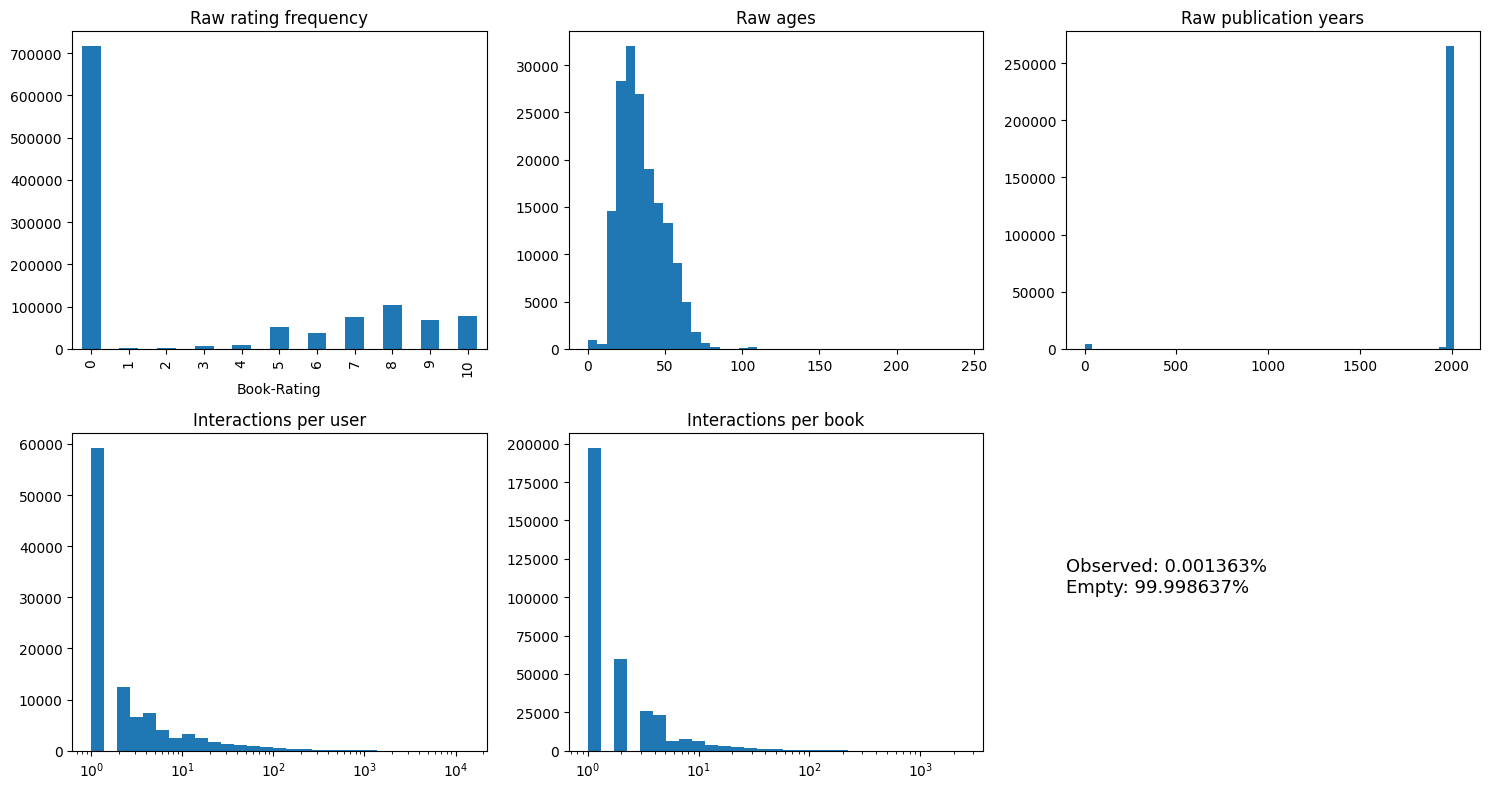

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
rating_dist.plot.bar(ax=axes[0,0], title='Raw rating frequency')
axes[0,1].hist(age_values.dropna(), bins=40); axes[0,1].set_title('Raw ages')
axes[0,2].hist(year_values.dropna(), bins=50); axes[0,2].set_title('Raw publication years')
axes[1,0].hist(per_user, bins=np.logspace(0, np.log10(per_user.max()+1), 30)); axes[1,0].set_xscale('log'); axes[1,0].set_title('Interactions per user')
axes[1,1].hist(per_book, bins=np.logspace(0, np.log10(per_book.max()+1), 30)); axes[1,1].set_xscale('log'); axes[1,1].set_title('Interactions per book')
axes[1,2].axis('off')
axes[1,2].text(0, .5, f'Observed: {100*observed/possible:.6f}%\nEmpty: {100*(1-observed/possible):.6f}%', fontsize=13)
plt.tight_layout(); plt.show()

### EDA findings and Silver decisions
- **Schema and missing values:** Users (278,858 × 4), Books (271,379 × 9) and Ratings (1,149,780 × 4), including ingestion timestamps, store raw source fields as strings; only Age has 110,762 missing values, so convert numeric fields and impute age in Silver.
- **Ratings:** 716,109 of 1,149,780 interactions are zero (62.28%); remove them from explicit training ratings but retain a separate seen-history index.
- **Age and publication year:** Ages range from 0 to 244 (1,248 outside 5–100), and publication years from 0 to 2050 (4,630 zero or future as of 2026); replace invalid ages with null then median-impute, and leave invalid publication years null.
- **Activity:** Median raw activity is one interaction for both users and books; 87.56% of active users and 94.62% of rated ISBNs have fewer than 10 interactions, so filter to at least 10 explicit ratings on both sides to reduce unreliable similarities while retaining a usable cohort.
- **Sparsity:** Of 75,676,205,182 possible catalog pairs, 1,031,175 distinct matched interactions exist (0.001363% observed, 99.998637% empty); explicit-only sparsity is 99.999493%, motivating support filtering and CSR storage.

## 3. Silver layer — cleaning and validation
The minimum support threshold is **10 distinct explicit ratings per user and per book**, applied iteratively until both conditions hold. This avoids leaving low-support entities after filtering the opposite side. Repeated user-book pairs, if any, are averaged after exact duplicate removal so a sparse entry never sums multiple scores. Text display values are standardized to title case; identifiers are uppercased/stripped (never converted to numbers for ISBNs).

In [15]:
def clean_text(series):
    return series.str.strip().str.replace(r'\s+', ' ', regex=True).str.title().replace('', pd.NA)

def clean_id(series):
    return series.str.strip().str.upper().replace('', pd.NA)

users = u.drop_duplicates().drop(columns='ingestion_timestamp').copy()
books = b.drop_duplicates().drop(columns='ingestion_timestamp').copy()
ratings = r.drop_duplicates().drop(columns='ingestion_timestamp').copy()
users['User-ID'] = pd.to_numeric(users['User-ID'], errors='coerce').astype('Int64')
ratings['User-ID'] = pd.to_numeric(ratings['User-ID'], errors='coerce').astype('Int64')
for table in (books, ratings):
    table['ISBN'] = clean_id(table['ISBN'])
users = users.dropna(subset=['User-ID']).drop_duplicates('User-ID')
books = books.dropna(subset=['ISBN']).drop_duplicates('ISBN')
ages = pd.to_numeric(users['Age'], errors='coerce')
ages = ages.where(ages.between(5, 100))
median_age = ages.median()
users['Age'] = ages.fillna(median_age).astype(float)
# Split from the right so multi-comma city names do not shift country/state.
parts = users['Location'].str.rsplit(',', n=2, expand=True).reindex(columns=range(3))
# A short location may omit city/state: align by number of components.
count = users['Location'].str.count(',').fillna(0)
users['city'] = clean_text(parts[0].where(count >= 2))
users['state'] = clean_text(parts[1].where(count >= 2, parts[0].where(count == 1)))
users['country'] = clean_text(parts[2].where(count >= 2, parts[1].where(count == 1, parts[0])))
users = users.drop(columns='Location')
for col in ['Book-Title','Book-Author','Publisher']:
    books[col] = clean_text(books[col])
books['Book-Title'] = books['Book-Title'].fillna('Unknown Title')
books['Book-Author'] = books['Book-Author'].fillna('Unknown Author')
years = pd.to_numeric(books['Year-Of-Publication'], errors='coerce')
books['Year-Of-Publication'] = years.where(years.between(1, current_year)).astype('Int64')
books = books.drop(columns=['Image-URL-S','Image-URL-M','Image-URL-L'])
ratings['Book-Rating'] = pd.to_numeric(ratings['Book-Rating'], errors='coerce')
# Save all valid known interactions (including zero) as a seen-history index for exclusion.
known = ratings[ratings['User-ID'].isin(users['User-ID']) & ratings['ISBN'].isin(books['ISBN'])].copy()
seen = known.loc[known['Book-Rating'].between(0, 10), ['User-ID','ISBN']].drop_duplicates()
explicit = known[known['Book-Rating'].between(1, 10)].copy()
explicit = explicit.groupby(['User-ID','ISBN'], as_index=False)['Book-Rating'].mean()
print('Median age used:', median_age)
print(f'Explicit, matched unique ratings before support filtering: {len(explicit):,}')
print(f'Users below 10: {(explicit.groupby("User-ID").size()<10).mean():.2%}; books below 10: {(explicit.groupby("ISBN").size()<10).mean():.2%}')

MIN_RATINGS = 10
ratings = explicit.copy()
iteration = 0
while True:
    before = len(ratings)
    uc = ratings['User-ID'].value_counts()
    bc = ratings['ISBN'].value_counts()
    ratings = ratings[ratings['User-ID'].isin(uc[uc >= MIN_RATINGS].index) &
                      ratings['ISBN'].isin(bc[bc >= MIN_RATINGS].index)].copy()
    iteration += 1
    print(f'Pass {iteration}: {len(ratings):,} ratings')
    if len(ratings) == before:
        break
assert not ratings.empty
users = users[users['User-ID'].isin(ratings['User-ID'])].copy()
books = books[books['ISBN'].isin(ratings['ISBN'])].copy()
seen = seen[seen['User-ID'].isin(users['User-ID']) & seen['ISBN'].isin(books['ISBN'])].copy()
assert ratings.groupby('User-ID').size().min() >= MIN_RATINGS
assert ratings.groupby('ISBN').size().min() >= MIN_RATINGS
assert ratings['Book-Rating'].between(1, 10).all()
assert users['Age'].between(5, 100).all()
assert books['Year-Of-Publication'].dropna().between(1, current_year).all()
assert not ratings.duplicated(['User-ID','ISBN']).any()
for name, table in [('users',users),('books',books),('ratings',ratings),('seen_history',seen)]:
    write_table(table, 'silver', name)
    print(name, table.shape)

Median age used: 32.0
Explicit, matched unique ratings before support filtering: 383,853
Users below 10: 90.32%; books below 10: 96.36%
Pass 1: 87,233 ratings
Pass 2: 57,938 ratings
Pass 3: 48,369 ratings
Pass 4: 44,679 ratings
Pass 5: 43,043 ratings
Pass 6: 42,204 ratings
Pass 7: 41,775 ratings
Pass 8: 41,604 ratings
Pass 9: 41,523 ratings
Pass 10: 41,496 ratings
Pass 11: 41,478 ratings
Pass 12: 41,469 ratings
Pass 13: 41,469 ratings
users (1820, 5)
books (2030, 5)
ratings (41469, 3)
seen_history (106767, 2)


## 4. Gold layer — model-ready data
A SciPy CSR sparse matrix stores explicit ratings only, with one row per user and one column per book. Index tables preserve the mapping from external IDs to matrix positions. A separate seen-history table excludes even zero-rated interactions from future recommendations; zero is not used as a training rating.

In [16]:
users = read_table('silver','users')
books = read_table('silver','books')
ratings = read_table('silver','ratings')
seen = read_table('silver','seen_history')
user_lookup = users[['User-ID']].sort_values('User-ID').reset_index(drop=True)
user_lookup['user_index'] = np.arange(len(user_lookup))
book_lookup = books[['ISBN','Book-Title','Book-Author']].sort_values('ISBN').reset_index(drop=True)
book_lookup['book_index'] = np.arange(len(book_lookup))
user_idx = ratings['User-ID'].map(user_lookup.set_index('User-ID')['user_index']).to_numpy(dtype=int)
book_idx = ratings['ISBN'].map(book_lookup.set_index('ISBN')['book_index']).to_numpy(dtype=int)
R = csr_matrix((ratings['Book-Rating'].to_numpy(dtype=np.float32), (user_idx,book_idx)),
               shape=(len(user_lookup),len(book_lookup)))
save_npz(ROOT/'gold'/'user_book_ratings.npz', R)
user_stats = ratings.groupby('User-ID', as_index=False).agg(average_rating=('Book-Rating','mean'), rating_count=('Book-Rating','size'))
book_stats = ratings.groupby('ISBN', as_index=False).agg(average_rating=('Book-Rating','mean'), rating_count=('Book-Rating','size'))
for name, table in [('user_lookup',user_lookup),('book_lookup',book_lookup),('user_aggregates',user_stats),('book_aggregates',book_stats),('seen_history',seen)]:
    write_table(table,'gold',name)
assert R.nnz == len(ratings)
print(f'Gold matrix: {R.shape}, nonzero entries: {R.nnz:,}, sparsity: {100*(1-R.nnz/(R.shape[0]*R.shape[1])):.2f}%')
print(f'Dense float32 size: {R.shape[0]*R.shape[1]*4/1e6:.2f} MB')
print(f'CSR size: {(R.data.nbytes+R.indices.nbytes+R.indptr.nbytes)/1e6:.2f} MB')
display(user_stats.head(), book_stats.head(), book_lookup.head())

Gold matrix: (1820, 2030), nonzero entries: 41,469, sparsity: 98.88%
Dense float32 size: 14.78 MB
CSR size: 0.34 MB


,User-ID,average_rating,rating_count
0,243,7.769231,13
1,254,8.45,20
2,638,9.454545,22
3,805,8.4,10
4,882,8.235294,17


,ISBN,average_rating,rating_count
0,0020199600,8.166667,12
1,0020442203,8.833333,12
2,002542730X,7.481481,27
3,0028604199,7.9,10
4,0060002050,7.545455,11


,ISBN,Book-Title,Book-Author,book_index
0,0020199600,Great Gatsby (Reissue),F. Scott Fitzgerald,0
1,0020442203,"Lion, The Witch And The Wardrobe",C.S. Lewis,1
2,002542730X,Politically Correct Bedtime Stories: Modern Ta...,James Finn Garner,2
3,0028604199,Once Upon A More Enlightened Time: More Politi...,James Finn Garner,3
4,0060002050,On A Wicked Dawn (Cynster Novels),Stephanie Laurens,4


## 5. Item-based collaborative filtering
Transpose the Gold matrix so that books are rows and users are columns. Cosine similarity is the dot product divided by the product of vector norms; similar books have similar explicit rating patterns. Missing entries are sparse zeros. Use the 50 nearest neighbors per highly rated seed (rating ≥ 8), weighted by the user's rating divided by 10. The final score is the sum of weighted similarities. If no rating is ≥ 8, use the user's highest-rated books as seeds. A user outside the Gold cohort receives a clearly labeled error rather than an arbitrary recommendation. Scores are ranking scores, not predicted ratings.

In [17]:
R = load_npz(ROOT/'gold'/'user_book_ratings.npz').tocsr()
book_user = R.T.tocsr()
lookup = read_table('gold','book_lookup').sort_values('book_index').reset_index(drop=True)
user_lookup = read_table('gold','user_lookup')
seen = read_table('gold','seen_history')
user_to_row = dict(zip(user_lookup['User-ID'], user_lookup['user_index']))
isbn_to_col = dict(zip(lookup['ISBN'], lookup['book_index']))
seen_by_user = seen.groupby('User-ID')['ISBN'].agg(set).to_dict()
model = NearestNeighbors(metric='cosine', algorithm='brute').fit(book_user)

def neighbors(i, k):
    distances, indices = model.kneighbors(book_user[i], n_neighbors=min(k+1, book_user.shape[0]))
    return [(int(j), max(0., float(1-d))) for j,d in zip(indices[0], distances[0]) if j != i and 1-d > 0][:k]

@lru_cache(maxsize=4096)
def cached_neighbors(i):
    return neighbors(i, 50)

def similar_books(title, n=10):
    if n <= 0:
        return pd.DataFrame(columns=['ISBN','title','author','similarity'])
    matches = lookup.index[lookup['Book-Title'].str.casefold() == title.strip().casefold()]
    if not len(matches):
        raise ValueError('Book title not found in the Gold catalog')
    i = int(matches[0])  # deterministic ISBN order for same-title editions
    result = []
    used_titles = {lookup.at[i,'Book-Title'].casefold()}
    for j, sim in neighbors(i, len(lookup)-1):
        key = lookup.at[j,'Book-Title'].casefold()
        if key in used_titles:
            continue
        used_titles.add(key)
        result.append({'ISBN':lookup.at[j,'ISBN'], 'title':lookup.at[j,'Book-Title'], 'author':lookup.at[j,'Book-Author'], 'similarity':sim})
        if len(result) == n:
            break
    return pd.DataFrame(result, columns=['ISBN','title','author','similarity'])

def seed_books(user_id):
    if user_id not in user_to_row:
        raise ValueError(f'User {user_id} is not in the Gold cohort')
    row = R[int(user_to_row[user_id])]
    pairs = sorted(zip(row.indices, row.data), key=lambda p: (-p[1], p[0]))
    high = [(int(i),float(v)) for i,v in pairs if v >= 8]
    return high if high else [(int(i),float(v)) for i,v in pairs[:5]]

def recommend(user_id, n=10):
    if n <= 0:
        return pd.DataFrame(columns=['ISBN','title','author','score'])
    seeds = seed_books(user_id)
    read_isbns = seen_by_user.get(user_id,set())
    read_titles = {lookup.at[isbn_to_col[x],'Book-Title'].casefold() for x in read_isbns if x in isbn_to_col}
    scores = defaultdict(float)
    for i, rating in seeds:
        for j, sim in cached_neighbors(i):
            if lookup.at[j,'ISBN'] not in read_isbns and lookup.at[j,'Book-Title'].casefold() not in read_titles:
                scores[j] += (rating/10.0)*sim
    ranked = sorted(scores, key=lambda j: (-scores[j], j))
    result, used_titles = [], set()
    for j in ranked:
        title = lookup.at[j,'Book-Title']
        if title.casefold() in used_titles:
            continue
        used_titles.add(title.casefold())
        result.append({'ISBN':lookup.at[j,'ISBN'], 'title':title, 'author':lookup.at[j,'Book-Author'], 'score':scores[j]})
        if len(result) == n:
            break
    return pd.DataFrame(result, columns=['ISBN','title','author','score'])

sample_title = lookup.at[int(np.argmax(np.asarray(book_user.getnnz(axis=1)))),'Book-Title']
print('Similar books to:', sample_title)
display(similar_books(sample_title))

Similar books to: The Lovely Bones: A Novel


,ISBN,title,author,similarity
0,0446672211,Where The Heart Is (Oprah'S Book Club (Paperba...,Billie Letts,0.219241
1,0316096199,Lucky : A Memoir,Alice Sebold,0.217959
2,0385504209,The Da Vinci Code,Dan Brown,0.178328
3,0316601950,The Pilot'S Wife : A Novel,Anita Shreve,0.176339
4,0743418174,Good In Bed,Jennifer Weiner,0.175819
5,0446531332,Nights In Rodanthe,Nicholas Sparks,0.170172
6,0688170528,The Pact: A Love Story,Jodi Picoult,0.168194
7,0316603287,The Lake House,James Patterson,0.166218
8,0684857820,Lucky,Alice Sebold,0.165055
9,0316284955,White Oleander : A Novel (Oprah'S Book Club),Janet Fitch,0.154238


## 6. Demo and sanity checks
Choose three distinct retained users who rated at least one book 8 or above. Show their highly rated books next to ten recommendations. Check that recommendations are unique, have positive scores, are ordered by descending score, and do not contain any ISBN already recorded for that user (including zero-rated interactions). This is a functional sanity check, not a held-out accuracy evaluation.

In [18]:
candidate_users = sorted(user_to_row)
demo_users = []
for uid in candidate_users:
    if any(v >= 8 for _,v in seed_books(uid)) and len(recommend(uid)) >= 10:
        demo_users.append(uid)
    if len(demo_users) == 3:
        break
assert len(demo_users) == 3
for uid in demo_users:
    recs = recommend(uid)
    favorites = pd.DataFrame([{'Highly rated book':lookup.at[i,'Book-Title'],'Rating':v} for i,v in seed_books(uid)])
    comparison = pd.concat([favorites.reset_index(drop=True), recs[['title','score']].rename(columns={'title':'Recommended book','score':'Weighted similarity'}).reset_index(drop=True)],axis=1)
    print(f'\nUser {uid} — {len(favorites)} highly rated books, {len(recs)} recommendations')
    display(comparison)
    assert len(recs) == 10 and recs['title'].str.casefold().is_unique
    assert not set(recs['ISBN']) & seen_by_user.get(uid,set())
    assert (recs['score'] > 0).all() and recs['score'].is_monotonic_decreasing
print('All three recommendation sanity checks passed.')


User 243 — 6 highly rated books, 10 recommendations


,Highly rated book,Rating,Recommended book,Weighted similarity
0,The Bean Trees,10.0,The Book Of Ruth (Oprah'S Book Club (Paperback)),0.384758
1,Memoirs Of A Geisha,10.0,The Body Farm,0.357511
2,The Pilot'S Wife : A Novel,9.0,From Potter'S Field,0.333838
3,Me Talk Pretty One Day,9.0,Animal Dreams,0.323098
4,Unnatural Exposure,9.0,Point Of Origin,0.302423
5,The General'S Daughter,9.0,Tears Of The Giraffe (No.1 Ladies Detective Ag...,0.295738
6,NaN,NaN,Pigs In Heaven,0.292385
7,NaN,NaN,Silent Prey,0.289635
8,NaN,NaN,The Sisterhood Of The Traveling Pants,0.287507
9,NaN,NaN,Serpent'S Tooth : A Peter Decker/Rina Lazarus ...,0.277645



User 254 — 17 highly rated books, 10 recommendations


,Highly rated book,Rating,Recommended book,Weighted similarity
0,American Gods,10.0,Harry Potter And The Sorcerer'S Stone (Harry P...,1.235740
1,Smoke And Mirrors: Short Fictions And Illusions,9.0,Prodigal Summer,0.834096
2,The Secret Life Of Bees,9.0,"The Amber Spyglass (His Dark Materials, Book 3)",0.800765
3,American Gods: A Novel,9.0,The Secret Garden,0.706944
4,The Bonesetter'S Daughter,9.0,Charlotte'S Web (Trophy Newbery),0.623517
5,Harry Potter And The Chamber Of Secrets (Book 2),9.0,The Silmarillion,0.610495
6,Harry Potter And The Chamber Of Secrets (Book 2),9.0,Speak,0.581970
7,Harry Potter And The Prisoner Of Azkaban (Book 3),9.0,The Name Of The Rose: Including Postscript To ...,0.569819
8,Harry Potter And The Prisoner Of Azkaban (Book 3),9.0,Brave New World,0.564916
9,Harry Potter And The Goblet Of Fire (Book 4),9.0,The Reptile Room (A Series Of Unfortunate Even...,0.557080



User 638 — 20 highly rated books, 10 recommendations


,Highly rated book,Rating,Recommended book,Weighted similarity
0,The Lovely Bones: A Novel,10.0,Midnight Bayou,1.587958
1,Four Blind Mice,10.0,The Gift,1.086744
2,The Catcher In The Rye,10.0,Trading Places,1.077797
3,Me Talk Pretty One Day,10.0,Dead Aim,1.077363
4,Barrel Fever : Stories And Essays (Barrel Fever),10.0,The Conspiracy Club,1.043328
5,The Pilot'S Wife : A Novel Tag: Author Of The ...,10.0,The Penwyth Curse,0.990364
6,Suzanne'S Diary For Nicholas,10.0,Someone To Watch Over Me : A Novel,0.957483
7,"The Two Towers (The Lord Of The Rings, Part 2)",10.0,Blow Fly: A Scarpetta Novel,0.948025
8,The Da Vinci Code,10.0,The Wedding,0.914569
9,Skipping Christmas,10.0,The Face,0.892380


All three recommendation sanity checks passed.


## Conclusion
The medallion design separates raw ingestion, cleaning, and model-ready data. Support filtering improves evidence for similarity; CSR avoids storing billions of missing interactions. Item-based collaborative filtering uses observed rating patterns and returns personalized unread books. Limitations include popularity bias, cold-start users/books, missing-as-zero cosine similarity, and lack of held-out evaluation. Future work could evaluate precision@10/recall@10 on a train/test split and compare with popularity and matrix-factorization baselines.

**Observed result:** The final Gold matrix contains 1,820 users, 2,030 books and 41,469 explicit ratings (98.88% sparsity). The three demonstrated users (243, 254, 638) each received ten unique unread recommendations.